# SWYNEX Task 2 — Exploratory Data Analysis

**Dataset:** UCI Adult Census Income Dataset  
**Internship:** SWYNEX Technologies  
**Task:** Task 2 — Exploratory Data Analysis

### Objective
Analyze the prepared Task 1 dataset using statistics and visualizations and identify at least five insights that could influence a machine-learning model or decision.

> **Before running:** place `adult_cleaned.csv` inside `data/processed/`.

## 1. Import libraries

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")

OUTPUT_DIR = Path("../visuals")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the prepared Task 1 dataset

In [2]:
DATA_PATH = Path("../data/processed/adult_cleaned.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "adult_cleaned.csv was not found. Put your Task 1 cleaned CSV in "
        "data/processed/ and run this cell again."
    )

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (48813, 15)


## 3. Normalize column names and detect important fields

In [3]:
def normalize_columns(dataframe):
    dataframe = dataframe.copy()
    original = list(dataframe.columns)
    normalized = []
    for col in dataframe.columns:
        col = str(col).strip().lower()
        col = re.sub(r"[^a-z0-9]+", "_", col).strip("_")
        normalized.append(col)
    dataframe.columns = normalized
    return dataframe, dict(zip(original, normalized))

df, column_mapping = normalize_columns(df)

print("Column mapping:")
for old, new in column_mapping.items():
    print(f"{old!r} -> {new!r}")

def find_col(candidates):
    for candidate in candidates:
        if candidate in df.columns:
            return candidate
    for col in df.columns:
        if any(candidate in col for candidate in candidates):
            return col
    return None

TARGET = find_col(["income", "income_class", "income_level", "salary", "target"])
AGE = find_col(["age"])
EDUCATION = find_col(["education", "education_num", "educational"])
OCCUPATION = find_col(["occupation"])
WORKCLASS = find_col(["workclass"])
HOURS = find_col(["hours_per_week", "hours"])
CAPITAL_GAIN = find_col(["capital_gain"])
SEX = find_col(["sex", "gender"])

detected = {
    "TARGET": TARGET,
    "AGE": AGE,
    "EDUCATION": EDUCATION,
    "OCCUPATION": OCCUPATION,
    "WORKCLASS": WORKCLASS,
    "HOURS": HOURS,
    "CAPITAL_GAIN": CAPITAL_GAIN,
    "SEX": SEX
}

print("\nDetected fields:")
for k, v in detected.items():
    print(f"{k}: {v}")

if TARGET is None:
    raise ValueError(
        "Could not automatically detect the income target. "
        f"Available columns: {list(df.columns)}"
    )

Column mapping:
'age' -> 'age'
'workclass' -> 'workclass'
'fnlwgt' -> 'fnlwgt'
'education' -> 'education'
'education_num' -> 'education_num'
'marital_status' -> 'marital_status'
'occupation' -> 'occupation'
'relationship' -> 'relationship'
'race' -> 'race'
'sex' -> 'sex'
'capital_gain' -> 'capital_gain'
'capital_loss' -> 'capital_loss'
'hours_per_week' -> 'hours_per_week'
'native_country' -> 'native_country'
'income' -> 'income'

Detected fields:
TARGET: income
AGE: age
EDUCATION: education
OCCUPATION: occupation
WORKCLASS: workclass
HOURS: hours_per_week
CAPITAL_GAIN: capital_gain
SEX: sex


## 4. Initial inspection

In [4]:
display(df.head())
display(df.tail())
display(df.sample(min(5, len(df)), random_state=42))

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique()
}).sort_values("missing", ascending=False))

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
48808,39,Private,215419,Bachelors,13,Divorced,Prof-specialty,Not-in-family,White,Female,0,0,36,United-States,<=50K.
48809,64,Private,321403,HS-grad,9,Widowed,Prof-specialty,Other-relative,Black,Male,0,0,40,United-States,<=50K.
48810,38,Private,374983,Bachelors,13,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,50,United-States,<=50K.
48811,44,Private,83891,Bachelors,13,Divorced,Adm-clerical,Own-child,Asian-Pac-Islander,Male,5455,0,40,United-States,<=50K.
48812,35,Self-emp-inc,182148,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,60,United-States,>50K.


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
14701,62,Private,96099,HS-grad,9,Never-married,Craft-repair,Not-in-family,White,Male,0,0,40,United-States,<=50K
15073,30,Private,174201,Some-college,10,Never-married,Craft-repair,Own-child,White,Male,0,0,40,United-States,<=50K
17837,46,Private,186078,Some-college,10,Never-married,Machine-op-inspct,Not-in-family,White,Female,0,0,45,United-States,<=50K
11732,41,Private,66118,Bachelors,13,Divorced,Prof-specialty,Own-child,White,Female,0,0,40,United-States,<=50K
35372,24,Private,199005,HS-grad,9,Never-married,Other-service,Own-child,White,Male,0,0,25,United-States,<=50K.


Rows: 48813
Columns: 15


,dtype,missing,missing_%,unique_values
age,int64,0,0.0,74
workclass,str,0,0.0,8
fnlwgt,int64,0,0.0,28523
education,str,0,0.0,16
education_num,int64,0,0.0,16
marital_status,str,0,0.0,7
occupation,str,0,0.0,14
relationship,str,0,0.0,6
race,str,0,0.0,5
sex,str,0,0.0,2


## 5. Data-quality checks

In [5]:
duplicate_count = int(df.duplicated().sum())
print("Duplicate rows:", duplicate_count)

missing_table = pd.DataFrame({
    "missing_values": df.isna().sum(),
    "missing_percentage": (df.isna().mean() * 100).round(2)
}).sort_values("missing_values", ascending=False)

display(missing_table)

print("Total missing cells:", int(df.isna().sum().sum()))

Duplicate rows: 0


,missing_values,missing_percentage
age,0,0.0
workclass,0,0.0
fnlwgt,0,0.0
education,0,0.0
education_num,0,0.0
marital_status,0,0.0
occupation,0,0.0
relationship,0,0.0
race,0,0.0
sex,0,0.0


Total missing cells: 0


## 6. Descriptive statistics

In [6]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Numerical columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

display(df[numeric_cols].describe().T)

if categorical_cols:
    display(df[categorical_cols].describe().T)

Numerical columns: ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']
Categorical columns: ['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country', 'income']


C:\Users\ACER\AppData\Local\Temp\ipykernel_2268\4115079707.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


,count,mean,std,min,25%,50%,75%,max
age,48813.0,38.647348,13.709005,17.0,28.0,37.0,48.0,90.0
fnlwgt,48813.0,189667.904964,105606.243360,12285.0,117555.0,178140.0,237620.0,1490400.0
education_num,48813.0,10.078688,2.570257,1.0,9.0,10.0,12.0,16.0
capital_gain,48813.0,1079.708705,7454.185982,0.0,0.0,0.0,0.0,99999.0
capital_loss,48813.0,87.554299,403.118605,0.0,0.0,0.0,0.0,4356.0
hours_per_week,48813.0,40.425051,12.390954,1.0,40.0,40.0,45.0,99.0


,count,unique,top,freq
workclass,48813,8,Private,36678
education,48813,16,HS-grad,15777
marital_status,48813,7,Married-civ-spouse,22372
occupation,48813,14,Prof-specialty,8976
relationship,48813,6,Husband,19709
race,48813,5,White,41736
sex,48813,2,Male,32631
native_country,48813,41,United-States,44666
income,48813,4,<=50K,24698


## 7. Target / income distribution

,count,percentage
income,,
<=50K,24698,50.60
<=50K.,12430,25.46
>50K,7839,16.06
>50K.,3846,7.88


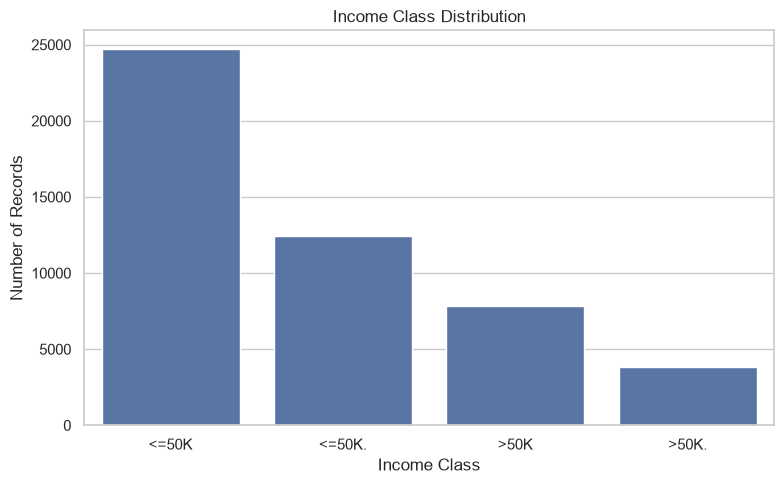

In [7]:
target_counts = df[TARGET].value_counts(dropna=False)
target_pct = df[TARGET].value_counts(normalize=True, dropna=False).mul(100).round(2)

target_table = pd.DataFrame({
    "count": target_counts,
    "percentage": target_pct
})
display(target_table)

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x=TARGET, order=target_counts.index)
plt.title("Income Class Distribution")
plt.xlabel("Income Class")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "income_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

## 8. Age analysis

count    48813.000000
mean        38.647348
std         13.709005
min         17.000000
25%         28.000000
50%         37.000000
75%         48.000000
max         90.000000
Name: age, dtype: float64

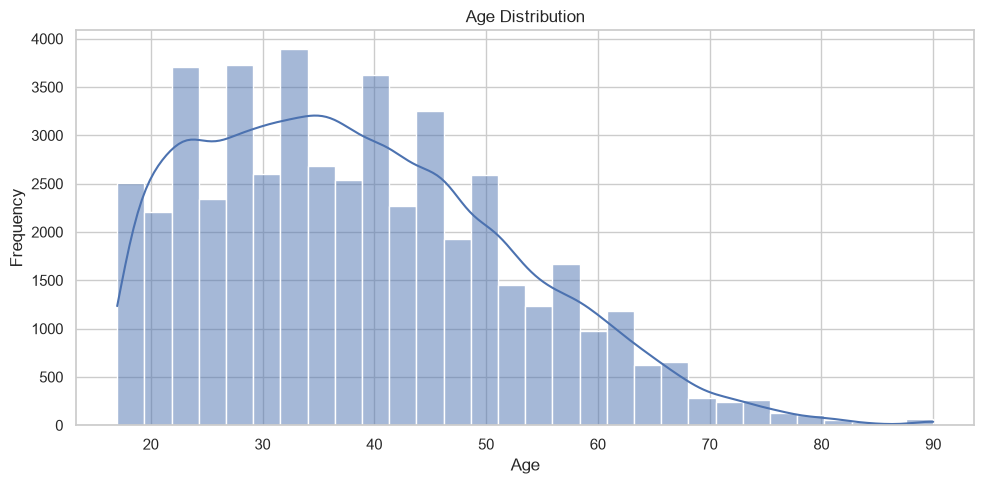

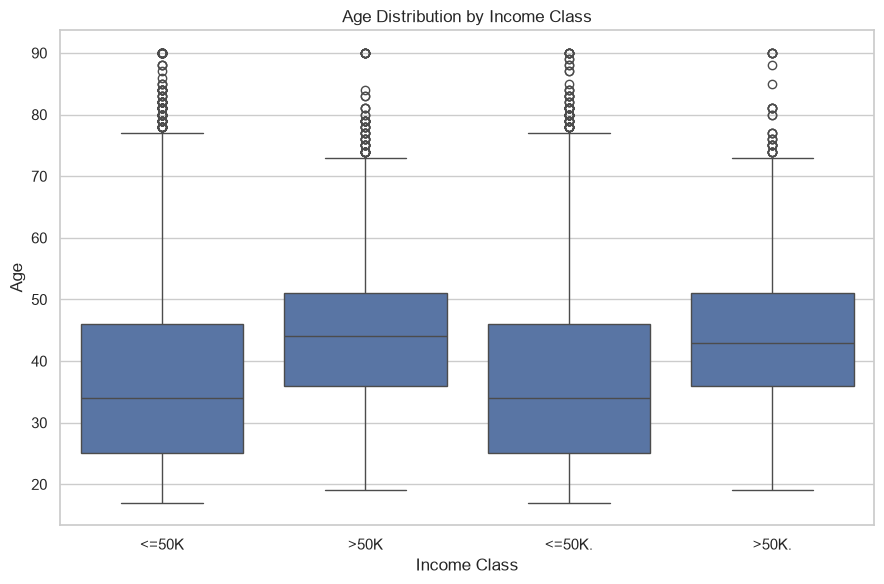

In [8]:
if AGE:
    display(df[AGE].describe())

    plt.figure(figsize=(10, 5))
    sns.histplot(data=df, x=AGE, bins=30, kde=True)
    plt.title("Age Distribution")
    plt.xlabel("Age")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "age_distribution.png", dpi=300, bbox_inches="tight")
    plt.show()

    plt.figure(figsize=(9, 6))
    sns.boxplot(data=df, x=TARGET, y=AGE)
    plt.title("Age Distribution by Income Class")
    plt.xlabel("Income Class")
    plt.ylabel("Age")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "age_vs_income.png", dpi=300, bbox_inches="tight")
    plt.show()
else:
    print("Age column not detected.")

## 9. Education analysis

education
HS-grad         15777
Some-college    10869
Bachelors        8020
Masters          2656
Assoc-voc        2060
11th             1812
Assoc-acdm       1601
10th             1389
7th-8th           954
Prof-school       834
9th               756
12th              656
Doctorate         594
5th-6th           508
1st-4th           245
Preschool          82
Name: count, dtype: int64

income,<=50K,<=50K.,>50K,>50K.
education,,,,
10th,62.71,31.03,4.46,1.80
11th,61.53,33.39,3.31,1.77
12th,60.98,31.71,5.03,2.29
1st-4th,65.31,31.43,2.45,0.82
5th-6th,62.20,32.48,3.15,2.17
7th-8th,63.42,30.08,4.19,2.31
9th,64.42,30.16,3.57,1.85
Assoc-acdm,50.09,24.11,16.55,9.24
Assoc-voc,49.56,25.10,17.52,7.82


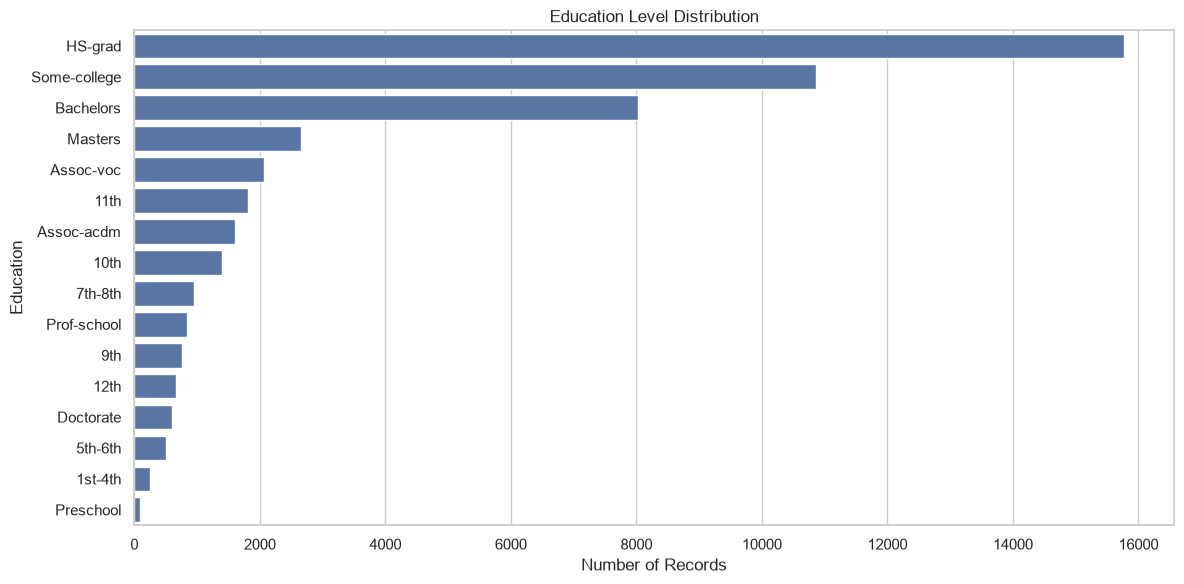

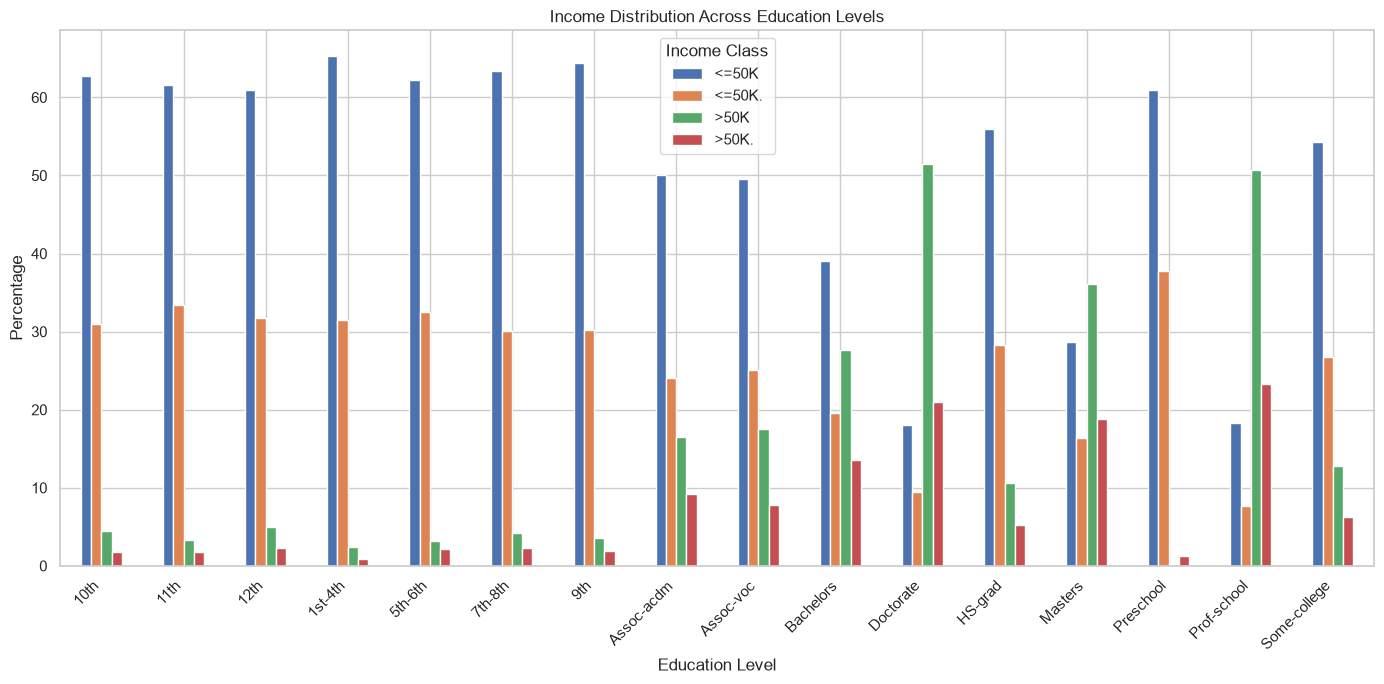

In [9]:
if EDUCATION:
    display(df[EDUCATION].value_counts(dropna=False).head(20))

    education_income = pd.crosstab(
        df[EDUCATION],
        df[TARGET],
        normalize="index"
    ).mul(100).round(2)

    display(education_income)

    plt.figure(figsize=(12, 6))
    sns.countplot(
        data=df,
        y=EDUCATION,
        order=df[EDUCATION].value_counts().head(20).index
    )
    plt.title("Education Level Distribution")
    plt.xlabel("Number of Records")
    plt.ylabel("Education")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "education_distribution.png", dpi=300, bbox_inches="tight")
    plt.show()

    education_income.plot(kind="bar", figsize=(14, 7))
    plt.title("Income Distribution Across Education Levels")
    plt.xlabel("Education Level")
    plt.ylabel("Percentage")
    plt.xticks(rotation=45, ha="right")
    plt.legend(title="Income Class")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "education_income.png", dpi=300, bbox_inches="tight")
    plt.show()
else:
    print("Education column not detected.")

## 10. Working-hours analysis

count    48813.000000
mean        40.425051
std         12.390954
min          1.000000
25%         40.000000
50%         40.000000
75%         45.000000
max         99.000000
Name: hours_per_week, dtype: float64

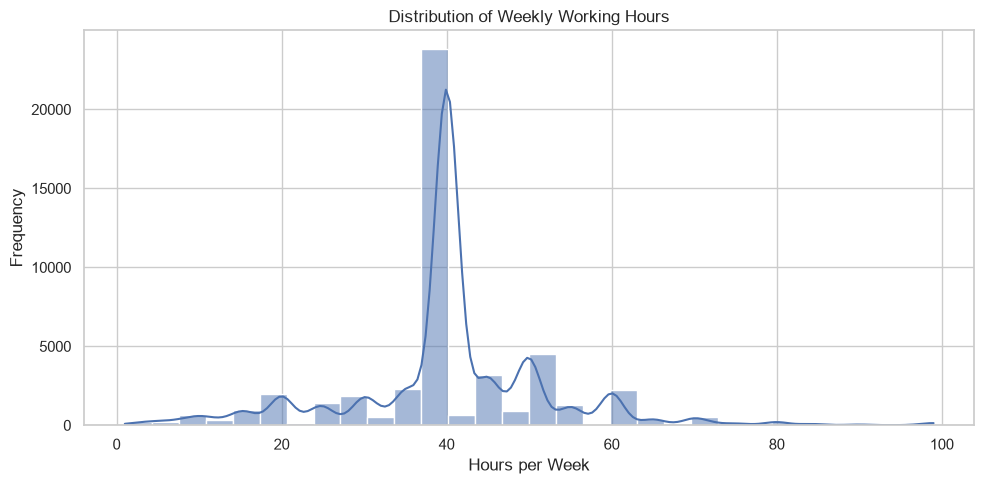

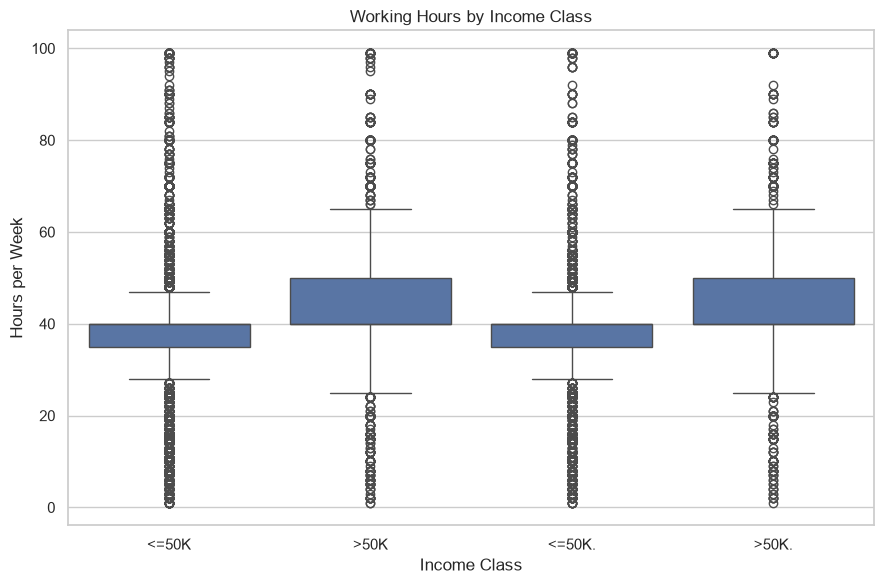

In [10]:
if HOURS:
    display(df[HOURS].describe())

    plt.figure(figsize=(10, 5))
    sns.histplot(data=df, x=HOURS, bins=30, kde=True)
    plt.title("Distribution of Weekly Working Hours")
    plt.xlabel("Hours per Week")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "hours_distribution.png", dpi=300, bbox_inches="tight")
    plt.show()

    plt.figure(figsize=(9, 6))
    sns.boxplot(data=df, x=TARGET, y=HOURS)
    plt.title("Working Hours by Income Class")
    plt.xlabel("Income Class")
    plt.ylabel("Hours per Week")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "hours_income.png", dpi=300, bbox_inches="tight")
    plt.show()
else:
    print("Working-hours column not detected.")

## 11. Occupation analysis

Top occupations:


occupation
Prof-specialty       8976
Craft-repair         6107
Exec-managerial      6084
Adm-clerical         5608
Sales                5504
Other-service        4919
Machine-op-inspct    3019
Transport-moving     2355
Handlers-cleaners    2071
Farming-fishing      1487
Tech-support         1445
Protective-serv       983
Priv-house-serv       240
Armed-Forces           15
Name: count, dtype: int64

income,<=50K,<=50K.,>50K,>50K.
occupation,,,,
Armed-Forces,53.33,13.33,6.67,26.67
Exec-managerial,34.47,17.74,32.35,15.45
Prof-specialty,43.78,22.26,22.83,11.13
Protective-serv,44.56,24.11,21.46,9.87
Tech-support,44.57,26.37,19.58,9.48
Sales,48.46,24.75,17.86,8.94
Craft-repair,51.83,25.53,15.21,7.43
Transport-moving,54.23,25.35,13.59,6.84
Adm-clerical,58.15,28.16,9.04,4.65


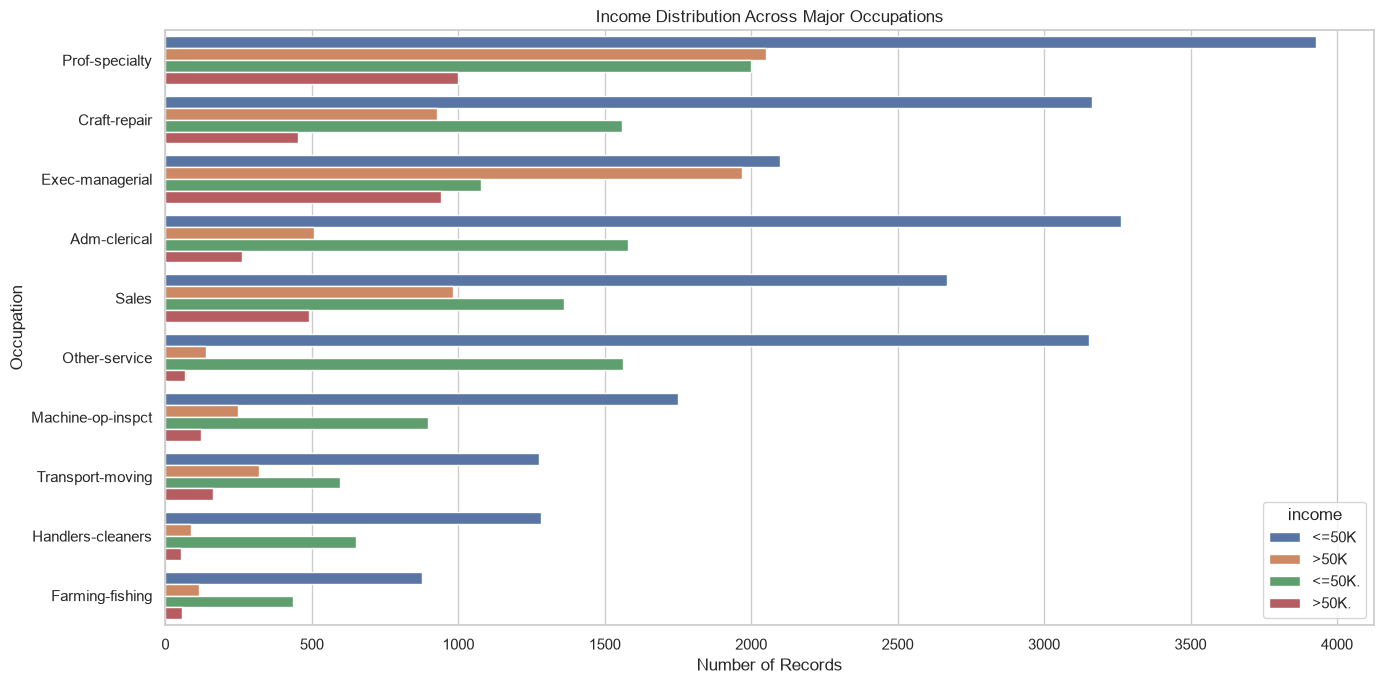

In [11]:
if OCCUPATION:
    print("Top occupations:")
    display(df[OCCUPATION].value_counts().head(15))

    occupation_income = pd.crosstab(
        df[OCCUPATION],
        df[TARGET],
        normalize="index"
    ).mul(100).round(2)

    display(occupation_income.sort_values(
        by=occupation_income.columns[-1],
        ascending=False
    ).head(15))

    top_occupations = df[OCCUPATION].value_counts().head(10).index

    plt.figure(figsize=(14, 7))
    sns.countplot(
        data=df[df[OCCUPATION].isin(top_occupations)],
        y=OCCUPATION,
        hue=TARGET,
        order=top_occupations
    )
    plt.title("Income Distribution Across Major Occupations")
    plt.xlabel("Number of Records")
    plt.ylabel("Occupation")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "occupation_income.png", dpi=300, bbox_inches="tight")
    plt.show()
else:
    print("Occupation column not detected.")

## 12. Workclass analysis

workclass
Private             36678
Self-emp-not-inc     3861
Local-gov            3136
State-gov            1981
Self-emp-inc         1694
Federal-gov          1432
Without-pay            21
Never-worked           10
Name: count, dtype: int64

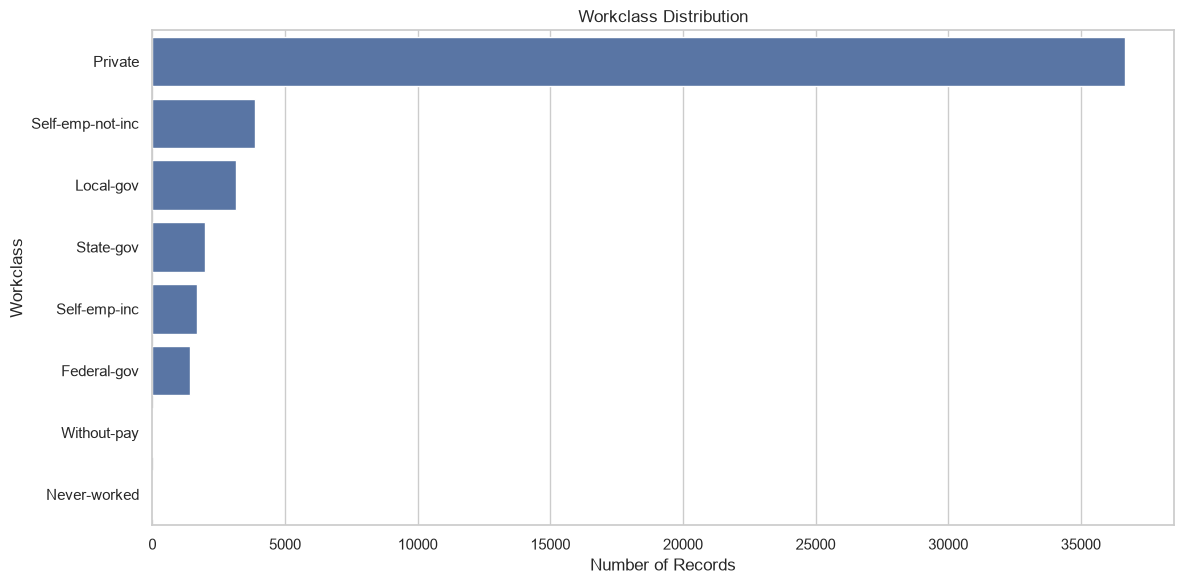

In [12]:
if WORKCLASS:
    display(df[WORKCLASS].value_counts(dropna=False))

    plt.figure(figsize=(12, 6))
    sns.countplot(
        data=df,
        y=WORKCLASS,
        order=df[WORKCLASS].value_counts().index
    )
    plt.title("Workclass Distribution")
    plt.xlabel("Number of Records")
    plt.ylabel("Workclass")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "workclass_distribution.png", dpi=300, bbox_inches="tight")
    plt.show()
else:
    print("Workclass column not detected.")

## 13. Capital-gain analysis

count    48813.000000
mean      1079.708705
std       7454.185982
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max      99999.000000
Name: capital_gain, dtype: float64

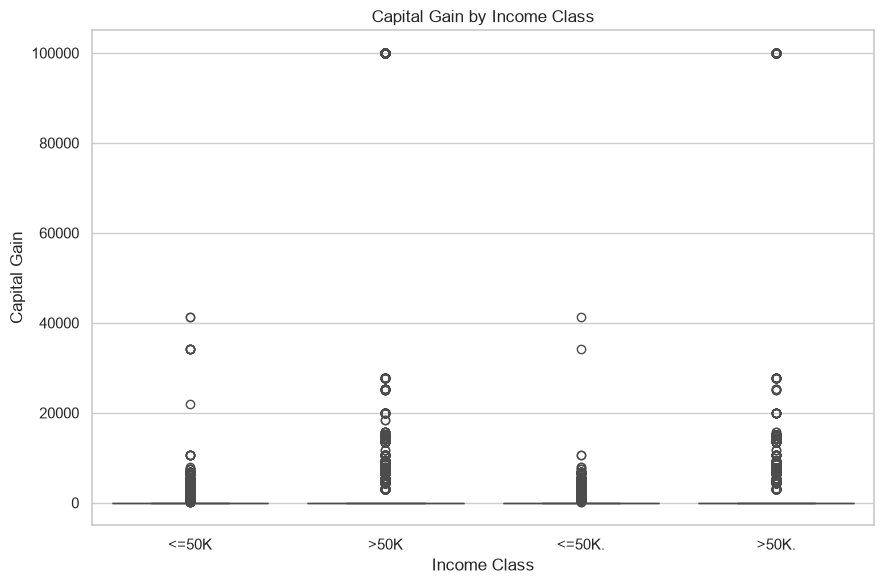

In [13]:
if CAPITAL_GAIN:
    display(df[CAPITAL_GAIN].describe())

    plt.figure(figsize=(9, 6))
    sns.boxplot(data=df, x=TARGET, y=CAPITAL_GAIN)
    plt.title("Capital Gain by Income Class")
    plt.xlabel("Income Class")
    plt.ylabel("Capital Gain")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "capital_gain_income.png", dpi=300, bbox_inches="tight")
    plt.show()
else:
    print("Capital-gain column not detected.")

## 14. Sex / gender analysis

income,<=50K,<=50K.,>50K,>50K.
sex,,,,
Female,59.22,29.85,7.29,3.65
Male,46.32,23.29,20.41,9.98


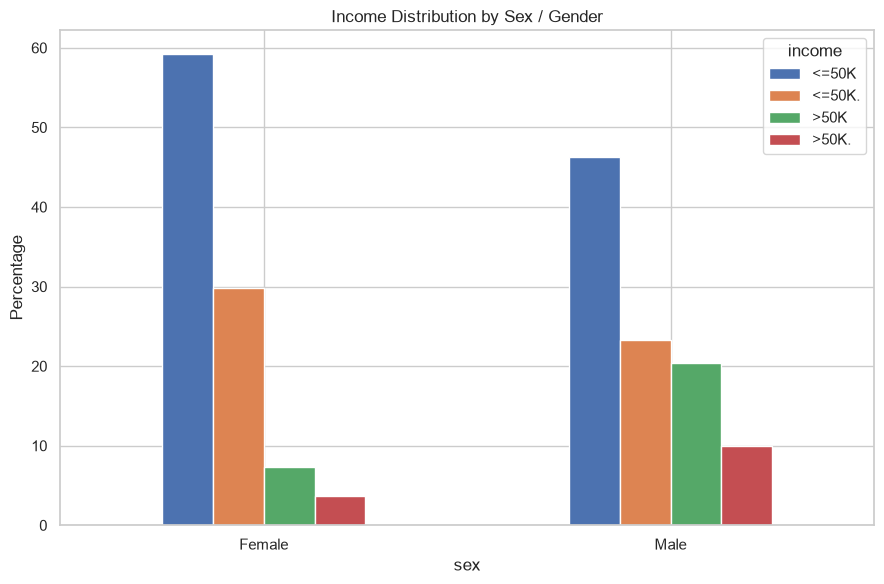

In [14]:
if SEX:
    sex_income = pd.crosstab(
        df[SEX],
        df[TARGET],
        normalize="index"
    ).mul(100).round(2)

    display(sex_income)

    sex_income.plot(kind="bar", figsize=(9, 6))
    plt.title("Income Distribution by Sex / Gender")
    plt.xlabel(SEX)
    plt.ylabel("Percentage")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "sex_income.png", dpi=300, bbox_inches="tight")
    plt.show()
else:
    print("Sex/gender column not detected.")

## 15. Correlation analysis

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week
age,1.000000,-0.076474,0.030760,0.077221,0.056908,0.071322
fnlwgt,-0.076474,1.000000,-0.038798,-0.003713,-0.004375,-0.013516
education_num,0.030760,-0.038798,1.000000,0.125186,0.080969,0.143872
capital_gain,0.077221,-0.003713,0.125186,1.000000,-0.031460,0.082154
capital_loss,0.056908,-0.004375,0.080969,-0.031460,1.000000,0.054440
hours_per_week,0.071322,-0.013516,0.143872,0.082154,0.054440,1.000000


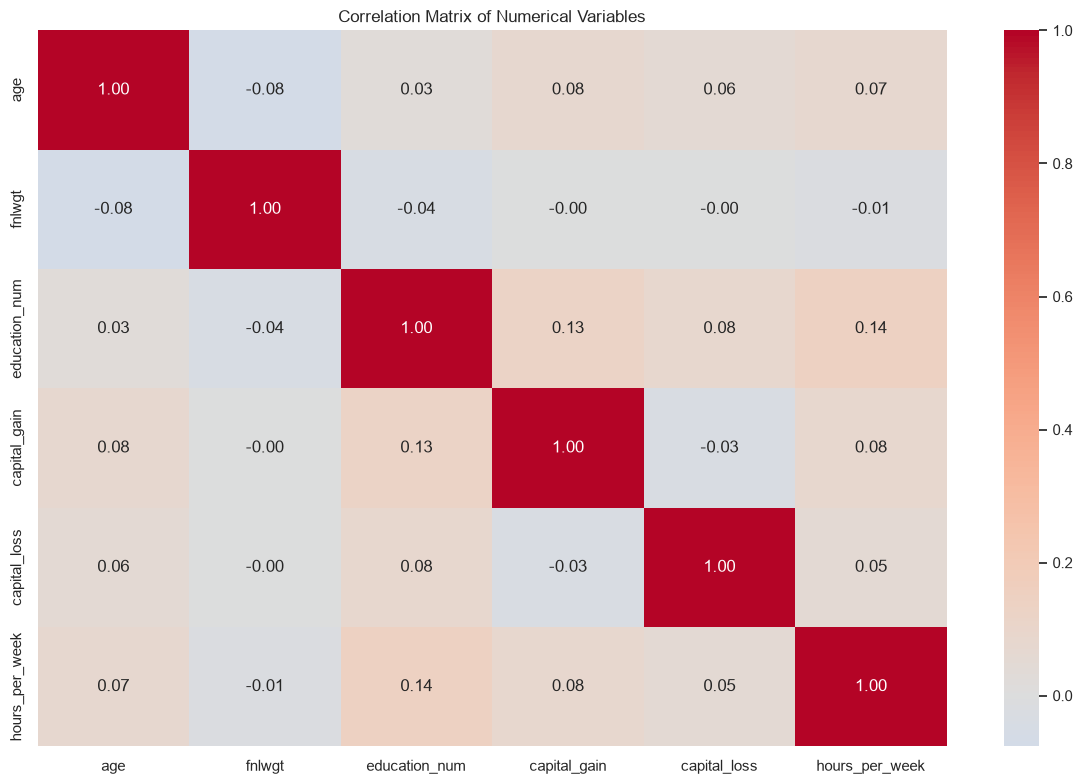

Strongest numerical correlations:


education_num  hours_per_week    0.143872
               capital_gain      0.125186
capital_gain   hours_per_week    0.082154
education_num  capital_loss      0.080969
age            capital_gain      0.077221
               fnlwgt           -0.076474
               hours_per_week    0.071322
               capital_loss      0.056908
capital_loss   hours_per_week    0.054440
fnlwgt         education_num    -0.038798
capital_gain   capital_loss     -0.031460
age            education_num     0.030760
fnlwgt         hours_per_week   -0.013516
               capital_loss     -0.004375
               capital_gain     -0.003713
dtype: float64

In [15]:
corr = df[numeric_cols].corr()

display(corr)

if len(numeric_cols) >= 2:
    plt.figure(figsize=(12, 8))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
    plt.title("Correlation Matrix of Numerical Variables")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "correlation_heatmap.png", dpi=300, bbox_inches="tight")
    plt.show()

    corr_pairs = (
        corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
            .stack()
            .sort_values(key=lambda s: s.abs(), ascending=False)
    )
    print("Strongest numerical correlations:")
    display(corr_pairs.head(15))

## 16. Outlier and skewness analysis

In [16]:
skewness = df[numeric_cols].skew().sort_values(ascending=False)
display(pd.DataFrame({"skewness": skewness}))

outlier_summary = []
for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = int(((df[col] < lower) | (df[col] > upper)).sum())
    outlier_summary.append([col, lower, upper, count])

outlier_table = pd.DataFrame(
    outlier_summary,
    columns=["feature", "lower_bound", "upper_bound", "outlier_count"]
).sort_values("outlier_count", ascending=False)

display(outlier_table)

,skewness
capital_gain,11.891093
capital_loss,4.568263
fnlwgt,1.439534
age,0.556775
hours_per_week,0.239643
education_num,-0.315007


,feature,lower_bound,upper_bound,outlier_count
5,hours_per_week,32.5,52.5,13489
3,capital_gain,0.0,0.0,4035
4,capital_loss,0.0,0.0,2282
2,education_num,4.5,16.5,1789
1,fnlwgt,-62542.5,417717.5,1453
0,age,-2.0,78.0,215


## 17. Automatic insight candidates

In [17]:
print("========== INSIGHT CANDIDATES ==========")

# 1. Target imbalance
majority_pct = target_pct.max()
minority_pct = target_pct.min()
majority_class = target_pct.idxmax()
minority_class = target_pct.idxmin()

print(f"1) Target distribution: {majority_class} = {majority_pct:.2f}%, "
      f"{minority_class} = {minority_pct:.2f}%.")
print("   Model impact: consider precision, recall, F1 and ROC-AUC in addition to accuracy.")

# 2. Education
if EDUCATION:
    edu = pd.crosstab(df[EDUCATION], df[TARGET], normalize="index") * 100
    high_class = target_counts.index[-1] if len(target_counts) else None
    if high_class in edu.columns:
        top_edu = edu[high_class].sort_values(ascending=False).head(3)
        print(f"2) Education: highest observed {high_class} proportions occur in:")
        print(top_edu.round(2).to_string())
        print("   Model impact: education may be a useful categorical predictor.")

# 3. Age
if AGE:
    age_by_target = df.groupby(TARGET)[AGE].agg(["mean", "median"]).round(2)
    print("3) Age by income class:")
    print(age_by_target.to_string())
    print("   Model impact: age may contain predictive information and may have non-linear effects.")

# 4. Hours
if HOURS:
    hours_by_target = df.groupby(TARGET)[HOURS].agg(["mean", "median"]).round(2)
    print("4) Working hours by income class:")
    print(hours_by_target.to_string())
    print("   Model impact: weekly hours may add predictive signal; inspect extremes.")

# 5. Occupation
if OCCUPATION:
    occ = pd.crosstab(df[OCCUPATION], df[TARGET], normalize="index") * 100
    if high_class in occ.columns:
        top_occ = occ[high_class].sort_values(ascending=False).head(5)
        print(f"5) Occupation: categories with the highest observed {high_class} proportions:")
        print(top_occ.round(2).to_string())
        print("   Model impact: occupation may be informative and needs suitable encoding.")

# 6. Capital gain
if CAPITAL_GAIN:
    cap = df.groupby(TARGET)[CAPITAL_GAIN].agg(["mean", "median"]).round(2)
    print("6) Capital gain by income class:")
    print(cap.to_string())
    print("   Model impact: capital gain can be highly skewed and should be checked carefully.")

========== INSIGHT CANDIDATES ==========
1) Target distribution: <=50K = 50.60%, >50K. = 7.88%.
   Model impact: consider precision, recall, F1 and ROC-AUC in addition to accuracy.
2) Education: highest observed >50K. proportions occur in:
education
Prof-school    23.26
Doctorate      21.04
Masters        18.83
   Model impact: education may be a useful categorical predictor.
3) Age by income class:
         mean  median
income               
<=50K   36.79    34.0
<=50K.  37.05    34.0
>50K    44.25    44.0
>50K.   44.33    43.0
   Model impact: age may contain predictive information and may have non-linear effects.
4) Working hours by income class:
         mean  median
income               
<=50K   38.84    40.0
<=50K.  38.84    40.0
>50K    45.47    40.0
>50K.   45.41    40.0
   Model impact: weekly hours may add predictive signal; inspect extremes.
5) Occupation: categories with the highest observed >50K. proportions:
occupation
Armed-Forces       26.67
Exec-managerial    15.45
Pro

## 18. Final summary

In [18]:
summary = pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "missing_values": df.isna().sum(),
    "unique_values": df.nunique()
})

display(summary)

print("EDA completed successfully.")
print(f"Rows analyzed: {len(df):,}")
print(f"Columns analyzed: {df.shape[1]}")
print(f"Duplicate rows: {df.duplicated().sum():,}")
print(f"Missing cells: {int(df.isna().sum().sum()):,}")
print(f"Visualizations saved to: {OUTPUT_DIR.resolve()}")

,data_type,missing_values,unique_values
age,int64,0,74
workclass,str,0,8
fnlwgt,int64,0,28523
education,str,0,16
education_num,int64,0,16
marital_status,str,0,7
occupation,str,0,14
relationship,str,0,6
race,str,0,5
sex,str,0,2


EDA completed successfully.
Rows analyzed: 48,813
Columns analyzed: 15
Duplicate rows: 0
Missing cells: 0
Visualizations saved to: C:\Users\ACER\Downloads\SWYNEX-Exploratory-Data-Analysis\SWYNEX-Exploratory-Data-Analysis\visuals
